# California Z500/T700 blocking-ridge / warm-anomaly events: Method A vs. Method B

**Question:** Over a box bounded roughly by the state of California, find persistent
(>= 5 consecutive days) periods where **500 hPa geopotential height** (Z500,
ridging/blocking) or **700 hPa temperature** (T700, warm spells) is more than 1, 2,
or 3 standard deviations (sigma) above normal, using ERA5 reanalysis, January-April,
1990-2025.

**Why two methods?** "Anomaly averaged over the state, in units of sigma" is
ambiguous once the state spans many grid points, each with its own local
climatological mean and standard deviation. This notebook computes the answer two
different, equally defensible ways and compares them directly.

- **Method A -- average-then-standardize.** Spatially average the *raw* field over
  the box first (one physical-unit time series per day), then standardize that
  single series against its own climatology. This is the standard construction for
  a box/region climate index (e.g. Nino3.4, PNA).
- **Method B -- standardize-then-average.** Standardize *each grid point* against
  its own local climatology first (putting every location on equal footing,
  regardless of how much its local day-to-day variability differs from its
  neighbors), then spatially average the resulting z-score field.

Both methods use the same event-detection rule: a run of >= `MIN_DURATION`
consecutive days at or above a given sigma threshold, tolerating up to `MAX_GAP`
sub-threshold days within the run (a brief dip doesn't split one persistent event
into two).

**Data:** `z500_t700_ca_<year>.nc`, produced by `get_z500_t700_ca.py` /
`job_array_get_z500_t700_ca.pbs` -- one file per year, daily-mean 500 hPa height (m)
and 700 hPa temperature (K) on a California bounding box (32.0-42.5N, 125.0-114.0W),
January-April only.

**Both year-detrended.** A fixed 36-year pooled climatology bakes in the
multi-decadal warming trend: recent years look artificially warm/high and early
years artificially cool/low, independent of actual synoptic extremity. Both
methods remove a linear year-trend (fit on annual Jan-Apr means) from the
climatological baseline before standardizing.

## 0. Setup

In [7]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from scipy.stats import linregress

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))  # 1990-2025 inclusive, excludes 2026
CLIM_WINDOW = 5                  # +/- days pooled around each calendar day for climatology
MIN_DURATION = 5                 # minimum consecutive days to count as an event
MAX_GAP = 1                      # max sub-threshold calendar days tolerated within an
                                  # event before it's considered two separate events --
                                  # lets a quasi-persistent, eddy-reinforced block that
                                  # briefly dips below threshold stay one event instead
                                  # of fragmenting into several
THRESHOLDS = [1, 2, 3]           # standard deviations
SIGN = 1                         # +1 = ridging/warm (as requested); -1 = troughs/cold
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]

## 1. Load the CA-box daily gridded data

In [8]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_z500_t700_ca.pbs first (see get_z500_t700_ca.py).'
    )

ds = xr.open_mfdataset(files, combine='by_coords')
weights = np.cos(np.deg2rad(ds.latitude))  # cosine-latitude area weights, reused by both methods
ds

<xarray.Dataset> Size: 67MB
Dimensions:    (time: 4329, latitude: 43, longitude: 45)
Coordinates:
  * time       (time) datetime64[ns] 35kB 1990-01-01 1990-01-02 ... 2025-04-30
  * latitude   (latitude) float64 344B 42.5 42.25 42.0 41.75 ... 32.5 32.25 32.0
  * longitude  (longitude) float64 360B 235.0 235.2 235.5 ... 245.5 245.8 246.0
Data variables:
    z500       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
    t700       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
Attributes: (12/18)
    long_name:                     Geopotential
    short_name:                    z
    units:                         m
    original_format:               WMO GRIB 1 with ECMWF local table
    ecmwf_local_table:             128
    ecmwf_parameter:               129
    ...                            ...
    rda_dataset_group:             ERA5 atmospheric pressure level analysis [...
    number_of_significant_digits:  7
    description:                   daily-mean 500 hPa geopotential height ove...
    script:                        get_z500_t700_ca.py
    box:                           lat 32.0-42.5, lon 235.0-246.0 (California)
    months:                        Jan-Apr

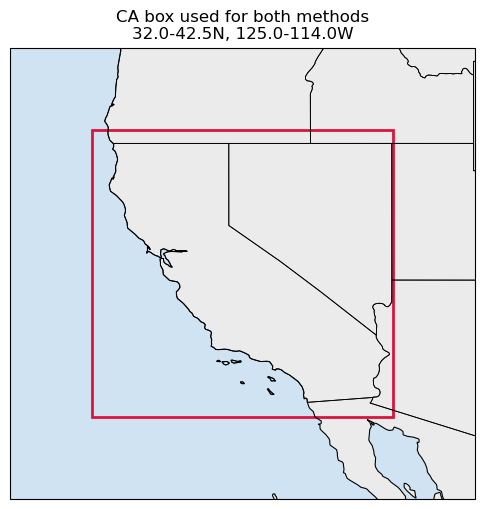

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

lat_min, lat_max = float(ds.latitude.min()), float(ds.latitude.max())
lon_min, lon_max = float(ds.longitude.min()), float(ds.longitude.max())
# ds.longitude is stored in 0-360E convention; convert to -180..180 for plotting
lon_min_180 = lon_min - 360 if lon_min > 180 else lon_min
lon_max_180 = lon_max - 360 if lon_max > 180 else lon_max

fig, ax = plt.subplots(figsize=(6, 7), subplot_kw={'projection': ccrs.PlateCarree()})
pad = 3
ax.set_extent([lon_min_180 - pad, lon_max_180 + pad, lat_min - pad, lat_max + pad], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='0.92')
ax.add_feature(cfeature.OCEAN, facecolor='#cfe3f2')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.STATES, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.6)

ax.add_patch(Rectangle(
    (lon_min_180, lat_min), lon_max_180 - lon_min_180, lat_max - lat_min,
    transform=ccrs.PlateCarree(), facecolor='none', edgecolor='crimson', linewidth=2,
))
ax.set_title(
    f'CA box used for both methods\n'
    f'{lat_min:.1f}-{lat_max:.1f}N, {-lon_min_180:.1f}-{-lon_max_180:.1f}W'
)
plt.show()

## 2. Shared helper functions

`climatology_dict`, `lookup_climatology`, and `find_events` are shared by both
methods: pooling and event-detection always operate along the time axis
regardless of whatever trailing shape the array has -- a 1-D box-mean series
(Method A) or a gridded `(time, lat, lon)` field (Method B).

In [10]:
def climatology_dict(time_index, vals, window=CLIM_WINDOW, compute_std=True):
    """Per-calendar-day mean (and optionally std), pooling +/-window days across all
    years, keyed by (month, day) rather than aligned to one specific index -- that's
    what lets this same function serve a 1-D box-mean series (Method A) or a
    gridded (time, lat, lon) field (Method B): pooling always happens along axis 0,
    whatever the trailing shape.
    """
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    clim_mean, clim_std = {}, {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        clim_mean[k] = vals[mask].mean(axis=0)
        if compute_std:
            clim_std[k] = vals[mask].std(axis=0)
    return (clim_mean, clim_std) if compute_std else clim_mean


def lookup_climatology(time_index, clim_dict):
    """Expand a (month, day) -> value dict into an array aligned to time_index."""
    md_key = list(zip(time_index.month, time_index.day))
    return np.array([clim_dict[k] for k in md_key])


def find_events(dates, sanom, threshold, min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP):
    """Group calendar days where sign*sanom >= threshold into events, tolerating
    short sub-threshold dips (up to max_gap calendar days) within an otherwise
    persistent run -- a quasi-persistent block reinforced by impinging eddies can
    briefly dip below threshold and reintensify without that being two events.
    Only merges gaps *within* one calendar-contiguous stretch of data: a gap across
    the real Apr->Jan year boundary is never bridged, since that date jump is far
    larger than any reasonable max_gap.
    """
    exceed = (sign * sanom) >= threshold
    n = len(dates)
    seg_id = np.zeros(n, dtype=int)
    for i in range(1, n):
        seg_id[i] = seg_id[i - 1] + (1 if (dates[i] - dates[i - 1]).days != 1 else 0)

    records = []
    for seg in np.unique(seg_id):
        idx = np.where(seg_id == seg)[0]
        seg_exceed = exceed[idx]
        runs = []
        start = None
        for j, val in enumerate(seg_exceed):
            if val and start is None:
                start = j
            elif not val and start is not None:
                runs.append((start, j - 1))
                start = None
        if start is not None:
            runs.append((start, len(seg_exceed) - 1))

        merged = []
        for run in runs:
            if merged and run[0] - merged[-1][1] - 1 <= max_gap:
                merged[-1] = (merged[-1][0], run[1])
            else:
                merged.append(list(run))
        merged = [tuple(m) for m in merged]

        for js, je in merged:
            s, e = idx[js], idx[je]
            duration = je - js + 1
            if duration >= min_duration:
                seg_sanom = sign * sanom[s:e + 1]
                records.append({
                    'start_date': dates[s].date(),
                    'end_date': dates[e].date(),
                    'duration_days': duration,
                    'n_gap_days': int((~exceed[s:e + 1]).sum()),
                    'peak_sanom': seg_sanom.max(),
                    'mean_sanom': seg_sanom.mean(),
                })
    return pd.DataFrame(records)

## 3. Method A: average-then-standardize

1. Cosine-latitude-weighted spatial mean of the *raw* Z500/T700 field over the CA
   box -> one physical-unit value per day.
2. Per-calendar-day climatology (mean, std) of that single box-mean series.
3. Linear year-trend fit and removed from the climatology baseline.
4. Standardize: `(value - detrended_climatological_mean) / climatological_std`.
5. Detect >= `MIN_DURATION`-day persistent runs at each sigma threshold.

In [11]:
z500_box = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
t700_box = ds.t700.weighted(weights).mean(dim=('latitude', 'longitude')).compute()

df = pd.DataFrame(
    {'z500': z500_box.values, 't700': t700_box.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]  # keep Jan-Apr only, in case source carries a stray day
df[['z500', 't700']].describe()

,z500,t700
count,4329.000000,4329.000000
mean,5659.962311,271.319546
std,92.032670,3.944485
min,5297.817250,257.827869
25%,5597.204648,268.596213
50%,5668.574255,271.574661
75%,5728.456609,274.193606
max,5891.593492,282.302358


In [12]:
def fit_year_trend(series, clim_mean, years, label=""):
    """Fit a linear year-trend in the climatology residual and return the fitted
    baseline shift for each day. Pooling all 36 years into one calendar-day mean
    (as climatology_dict() does) silently bakes a multi-decadal trend into the
    baseline -- anomalies look artificially warm/high in recent years and
    artificially cool/low in the 1990s, independent of actual synoptic extremity.
    The trend is estimated from annual Jan-Apr means (36 points) rather than daily
    residuals, to avoid autocorrelation inflating the apparent significance.
    """
    residual = series - clim_mean
    annual_mean_residual = pd.Series(residual, index=years).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(annual_mean_residual.index.values, annual_mean_residual.values)
    print(f'{label}: year-trend = {slope * 10:+.3f} per decade (p = {p:.3f}, r = {r:.2f})')
    return intercept + slope * years


for col in ["z500", "t700"]:
    clim_mean, clim_std = climatology_dict(df.index, df[col].values)
    m = lookup_climatology(df.index, clim_mean)
    s = lookup_climatology(df.index, clim_std)
    trend = fit_year_trend(df[col].values, m, df.index.year.values, label=col)
    df[f"{col}_clim_mean"] = m + trend
    df[f"{col}_clim_std"] = s
    df[f"{col}_sanom"] = (df[col] - df[f"{col}_clim_mean"]) / df[f"{col}_clim_std"]

df[["z500_sanom", "t700_sanom"]].describe()

z500: year-trend = +7.405 per decade (p = 0.045, r = 0.34)
t700: year-trend = +0.204 per decade (p = 0.168, r = 0.23)


,z500_sanom,t700_sanom
count,4329.000000,4329.000000
mean,0.000094,-0.000150
std,0.993207,0.994326
min,-3.882557,-3.523486
25%,-0.703784,-0.683446
50%,0.092674,0.076724
75%,0.746074,0.747162
max,2.286580,2.374307


In [13]:
events_A = []
dates = df.index
for col, label in VARS:
    sanom = df[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_A.append(ev)

events_methodA = pd.concat(events_A, ignore_index=True)
events_methodA = events_methodA.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'Method A: {len(events_methodA)} events found (>= {MIN_DURATION} days, gap tolerance {MAX_GAP} day(s))')
events_methodA.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

Method A: 97 events found (>= 5 days, gap tolerance 1 day(s))


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,48,6.791667,12.0
700 hPa temperature (warm),1,49,7.571429,18.0


## 4. Method B: standardize-then-average

1. Standardize *each grid point* against its own local climatology, with a
   per-pixel linear year-trend fit (same idea as `fit_year_trend` above,
   generalized from one series to every grid point at once via broadcasting).
2. Cosine-latitude-weighted spatial mean of the resulting z-score field -> one
   dimensionless value per day.
3. Detect >= `MIN_DURATION`-day persistent runs at each sigma threshold, with the
   exact same `find_events` used for Method A.

In [14]:
def gridpoint_sanom_da(da, window=CLIM_WINDOW):
    """Per-grid-point standardized anomaly, year-detrended the same way as
    fit_year_trend() in Method A -- but the linear year-trend is fit per grid
    point (vectorized over lat/lon via broadcasting) instead of on one spatial
    average. Returned as an xr.DataArray with da's own dims/coords, so it can be
    .sel()/.weighted() averaged over any sub-box exactly like the raw field.
    """
    time_index = pd.to_datetime(da.time.values)
    vals = da.load().values  # (time, lat, lon)
    clim_mean, clim_std = climatology_dict(time_index, vals, window, compute_std=True)
    m = lookup_climatology(time_index, clim_mean)
    s = lookup_climatology(time_index, clim_std)

    # per-grid-point linear year-trend in the climatology residual -- same OLS
    # idea as fit_year_trend() above, generalized from one box-mean series to
    # every grid point at once via array broadcasting.
    residual = vals - m
    years = time_index.year.values
    uniq_years = np.unique(years)
    annual_mean = np.stack([residual[years == y].mean(axis=0) for y in uniq_years])  # (n_years, lat, lon)
    x = uniq_years - uniq_years.mean()
    y_bar = annual_mean.mean(axis=0)
    slope = (x[:, None, None] * (annual_mean - y_bar)).sum(axis=0) / (x ** 2).sum()
    intercept = y_bar - slope * uniq_years.mean()
    trend = intercept[None, :, :] + slope[None, :, :] * years[:, None, None]

    sanom = (vals - (m + trend)) / s
    return xr.DataArray(sanom, dims=da.dims, coords=da.coords)


z500_grid_sanom = gridpoint_sanom_da(ds["z500"])
t700_grid_sanom = gridpoint_sanom_da(ds["t700"])

In [15]:
z500_avgsanom = z500_grid_sanom.weighted(weights).mean(dim=("latitude", "longitude")).compute()
t700_avgsanom = t700_grid_sanom.weighted(weights).mean(dim=("latitude", "longitude")).compute()

df_methodB = pd.DataFrame(
    {"z500_sanom": z500_avgsanom.values, "t700_sanom": t700_avgsanom.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()
df_methodB = df_methodB[df_methodB.index.month.isin([1, 2, 3, 4])]
df_methodB.describe()

,z500_sanom,t700_sanom
count,4329.000000,4329.000000
mean,0.000141,-0.000055
std,0.904328,0.851870
min,-3.586191,-3.090296
25%,-0.644410,-0.587818
50%,0.087494,0.063374
75%,0.680107,0.637187
max,2.113701,2.078393


In [16]:
events_B = []
dates_B = df_methodB.index
for col, label in VARS:
    sanom = df_methodB[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates_B, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_B.append(ev)

events_methodB = pd.concat(events_B, ignore_index=True)
events_methodB = events_methodB.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'Method B: {len(events_methodB)} events found (>= {MIN_DURATION} days, gap tolerance {MAX_GAP} day(s))')
events_methodB.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

Method B: 64 events found (>= 5 days, gap tolerance 1 day(s))


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,34,6.794118,11.0
700 hPa temperature (warm),1,30,7.166667,18.0


## 5. Comparison

In [17]:
print('Event-count comparison, CA box (the state), Method A vs Method B:')
compare_ab = pd.DataFrame({
    'Method A (avg-then-std)': events_methodA.groupby(['variable', 'threshold_sd']).size(),
    'Method B (std-then-avg)': events_methodB.groupby(['variable', 'threshold_sd']).size(),
}).fillna(0).astype(int)
compare_ab

Event-count comparison, CA box (the state), Method A vs Method B:


,,Method A (avg-then-std),Method B (std-then-avg)
variable,threshold_sd,,
500 hPa height (ridging),1,48,34
700 hPa temperature (warm),1,49,30


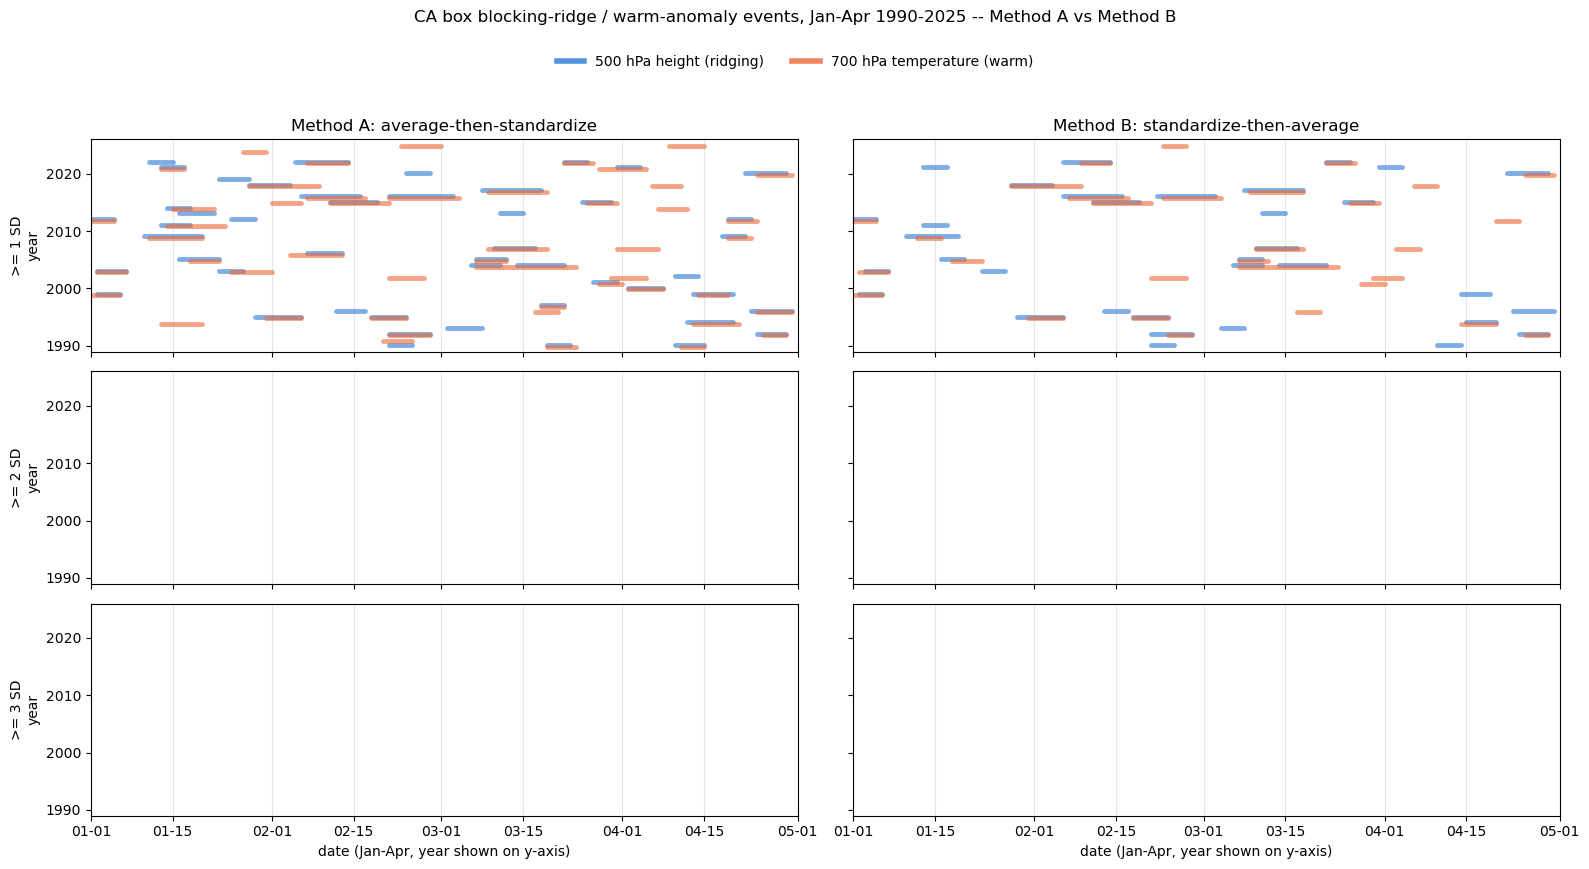

In [18]:
COLOR = {"500 hPa height (ridging)": "#2a78d6", "700 hPa temperature (warm)": "#eb6834"}
Y_OFFSET = {"500 hPa height (ridging)": 0.1, "700 hPa temperature (warm)": -0.18}

fig, axes = plt.subplots(len(THRESHOLDS), 2, figsize=(16, 8), sharex=True, sharey=True)
for col_idx, (method_label, edf) in enumerate([
    ("Method A: average-then-standardize", events_methodA),
    ("Method B: standardize-then-average", events_methodB),
]):
    for row_idx, thr in enumerate(THRESHOLDS):
        ax = axes[row_idx, col_idx]
        sub = edf[edf.threshold_sd == thr]
        for _, row in sub.iterrows():
            year = row.start_date.year
            x0 = pd.Timestamp(2000, row.start_date.month, row.start_date.day)
            x1 = (pd.Timestamp(2000, row.end_date.month, row.end_date.day)
                  if row.end_date.year == row.start_date.year else pd.Timestamp(2000, 4, 30))
            y = year + Y_OFFSET[row.variable]
            ax.plot([x0, x1], [y, y], color=COLOR[row.variable], linewidth=3.5,
                     alpha=0.6, solid_capstyle="round")
        if col_idx == 0:
            ax.set_ylabel(f">= {thr} SD\nyear")
        ax.set_ylim(1989, 2026)
        # explicit x-limits instead of matplotlib's default autoscale, which pads a
        # few days into Dec 1999 on the left and cuts awkwardly past Apr 30 on the
        # right; 05-01 gives the last event's line a one-day buffer from the edge.
        ax.set_xlim(pd.Timestamp(2000, 1, 1), pd.Timestamp(2000, 5, 1))
        # ticks as MM-DD, not the full 2000-MM-DD -- the placeholder year 2000 used
        # to lay all events on one calendar axis isn't real data and shouldn't show.
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
        ax.grid(axis="x", color="0.9")
        if row_idx == 0:
            ax.set_title(method_label)
axes[-1, 0].set_xlabel("date (Jan-Apr, year shown on y-axis)")
axes[-1, 1].set_xlabel("date (Jan-Apr, year shown on y-axis)")
handles = [plt.Line2D([0], [0], color=c, linewidth=4, alpha=0.8) for c in COLOR.values()]
fig.legend(handles, COLOR.keys(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04), frameon=False)
fig.suptitle("CA box blocking-ridge / warm-anomaly events, Jan-Apr 1990-2025 -- Method A vs Method B", y=1.08)
fig.tight_layout()
plt.show()

## 6. Sensitivity: does a wider climatology-pooling window close the gap?

Method B estimates a separate climatological standard deviation at every grid
point (~1,935 of them), each from only that pixel's own pooled samples
(`CLIM_WINDOW=5` -> ~36 years x 11 days ~ 396 samples). Each pixel's estimate
carries its own sampling error, and that error is much less spatially coherent
than the real atmospheric signal -- so when the z-score field is averaged back
down to one series, the real signal survives but some of the per-pixel noise
partially cancels, shrinking the result's variance below 1 (std ~0.90/0.85 for
Method B vs ~0.99/0.99 for Method A, both at `CLIM_WINDOW=5`, above).

If that's really the mechanism, pooling *more* days per pixel (a wider
`CLIM_WINDOW`) should give a less noisy per-pixel standard deviation, and the
gap between Method A and Method B should shrink. This re-runs Method B with
`CLIM_WINDOW = 5, 10, 15` to test that directly (Method A is unaffected, since
it only ever estimates one climatology regardless of window width, and is
included below only as a fixed reference line).

In [19]:
sensitivity_windows = [5, 10, 15]
sensitivity_std = {}       # window -> {col: std of area-averaged z-score series}
sensitivity_counts = {}    # window -> events_df for that window

for window in sensitivity_windows:
    z500_w = gridpoint_sanom_da(ds['z500'], window=window)
    t700_w = gridpoint_sanom_da(ds['t700'], window=window)
    z500_avg_w = z500_w.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
    t700_avg_w = t700_w.weighted(weights).mean(dim=('latitude', 'longitude')).compute()

    df_w = pd.DataFrame(
        {'z500_sanom': z500_avg_w.values, 't700_sanom': t700_avg_w.values},
        index=pd.to_datetime(ds.time.values),
    ).sort_index()
    df_w = df_w[df_w.index.month.isin([1, 2, 3, 4])]
    sensitivity_std[window] = df_w[['z500_sanom', 't700_sanom']].std().to_dict()

    events_w = []
    for col, label in VARS:
        sanom = df_w[f'{col}_sanom'].values
        for thr in THRESHOLDS:
            ev = find_events(df_w.index, sanom, threshold=thr)
            ev.insert(0, 'threshold_sd', thr)
            ev.insert(0, 'variable', label)
            events_w.append(ev)
    sensitivity_counts[window] = pd.concat(events_w, ignore_index=True)

    print(f'CLIM_WINDOW={window:>2}: std(z500_sanom)={sensitivity_std[window]["z500_sanom"]:.3f}, '
          f'std(t700_sanom)={sensitivity_std[window]["t700_sanom"]:.3f}')

print()
print('Event counts at >= 1 SD, Method A (fixed reference) vs Method B at each CLIM_WINDOW:')
sensitivity_table = pd.DataFrame({
    'Method A (reference)': events_methodA[events_methodA.threshold_sd == 1].groupby('variable').size(),
    **{
        f'Method B (window={w})': sensitivity_counts[w][sensitivity_counts[w].threshold_sd == 1].groupby('variable').size()
        for w in sensitivity_windows
    },
}).fillna(0).astype(int)
sensitivity_table

CLIM_WINDOW= 5: std(z500_sanom)=0.904, std(t700_sanom)=0.852
CLIM_WINDOW=10: std(z500_sanom)=0.904, std(t700_sanom)=0.852
CLIM_WINDOW=15: std(z500_sanom)=0.904, std(t700_sanom)=0.852

Event counts at >= 1 SD, Method A (fixed reference) vs Method B at each CLIM_WINDOW:


,Method A (reference),Method B (window=5),Method B (window=10),Method B (window=15)
variable,,,,
500 hPa height (ridging),48,34,33,32
700 hPa temperature (warm),49,30,33,31


**Result: the gap does not close.** The area-averaged z-score series' own
standard deviation barely moves across `CLIM_WINDOW = 5, 10, 15` (see the
printed values above), and the >= 1 SD event counts stay in a narrow band
rather than converging toward Method A's 48/49. A separate check extending the
range all the way from `CLIM_WINDOW=1` to `CLIM_WINDOW=25` confirms this isn't
just a too-narrow test: each grid point's own climatological standard
deviation *does* get measurably smoother over that range (the spread of
per-pixel std estimates across the domain drops by about 15%, confirming the
pooling window is doing what it's supposed to), yet the final area-averaged
z-score series' standard deviation only moves from 0.9043 to 0.9020 -- far too
small to explain the ~0.09-0.14 gap against Method A's ~0.99.

**This falsifies the finite-sample-noise explanation from Section 5/7.** If
noisy per-pixel standard-deviation estimates were the main driver of Method
B's smaller variance, a much wider pooling window should have shrunk the gap
noticeably. It didn't.

**Revised explanation: this is structural, not a sampling-noise artifact.**
Standardizing each grid point before averaging implicitly reweights every
location by the inverse of its own *local* standard deviation, on top of the
cosine-latitude area weight -- a location with larger local day-to-day
variability gets divided by a larger number and so contributes less per unit
of physical anomaly to the final average than a location with smaller local
variability. This reweighting depends only on the *population* difference in
local variability across the domain (coastal vs. interior, etc.), not on how
precisely that variability is estimated -- which is exactly why widening
`CLIM_WINDOW` doesn't change the result. If the real synoptic ridging/warm
anomaly isn't exactly proportional to each location's own local standard
deviation, this inverse-variance reweighting systematically changes the
area-averaged signal relative to Method A's simple physically-weighted
average -- regardless of sample size.

## 7. Conclusions

- **Both methods agree at the extremes.** No event sustains >= 2 sigma (let alone
  3 sigma) for 5 or more continuous days anywhere in the 36-year Jan-Apr CA-box
  record, under either method -- the >= 2 SD and >= 3 SD panels above are empty.
  This is a genuine finding about persistent mid-tropospheric ridging over
  California in this season, not a detection failure: single days do spike above
  2 sigma, but never stay there for a full 5-day run.
- **The methods disagree somewhat at >= 1 sigma.** Method A (average-then-
  standardize) finds more persistent events than Method B (standardize-then-
  average) -- 48 vs 34 for Z500 ridging, 49 vs 30 for T700 warm spells.
- **Section 6's sensitivity test rules out finite-sample noise as the cause.**
  Widening `CLIM_WINDOW` (giving each grid point a less noisy local
  standard-deviation estimate) barely moves Method B's result at all, even
  across a 1-to-25-day range where the per-pixel std estimates themselves
  measurably smooth out. The real explanation is structural: standardizing
  each grid point before averaging implicitly reweights every location by the
  inverse of its own local standard deviation, on top of area weighting --
  which changes the result regardless of how well that local standard
  deviation is estimated, and so cannot be fixed by pooling more days.
- **Practical takeaway.** The choice of standardization order matters
  quantitatively for the >= 1 sigma count, but does not change the qualitative
  conclusion: there is no sustained (>= 5 day) >= 2 sigma ridging/warm event over
  California in January-April, 1990-2025, under any reasonable definition of
  "anomaly averaged over the state".

## 8. Refinement: histogram of daily anomalies, and a 5-day running-mean definition

Two follow-up questions on the "no sustained >= 2 sigma event" finding above:

1. Do individual days ever reach 2 sigma? The >= 2/3 SD rows in Sections 3/4
   being empty means no **5-day run** stays at/above 2 sigma -- it does not mean
   no single day ever reaches 2 sigma. A histogram of the daily standardized
   anomaly (Method A) answers this directly.
2. What if the anomaly itself is defined from a 5-day running mean of the raw
   field, rather than requiring every one of 5 raw daily values to
   individually clear the threshold? Smoothing first and checking the
   persistence criterion on the smoothed series is a materially different (and
   less strict) definition of "5-day persistent event."

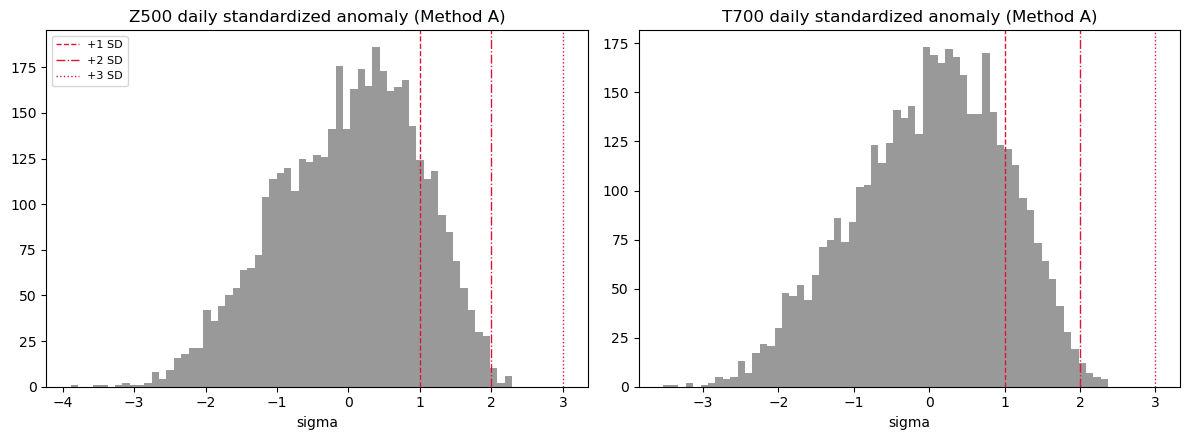

Days at/above each threshold, Method A, daily values with NO persistence filter:
  Z500 >= 1 SD: 708 of 4329 days (16.35%)
  Z500 >= 2 SD: 15 of 4329 days (0.35%)
  Z500 >= 3 SD: 0 of 4329 days (0.00%)
  T700 >= 1 SD: 726 of 4329 days (16.77%)
  T700 >= 2 SD: 26 of 4329 days (0.60%)
  T700 >= 3 SD: 0 of 4329 days (0.00%)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ['z500_sanom', 't700_sanom'], ['Z500', 'T700']):
    ax.hist(df[col], bins=60, color='0.6', edgecolor='none')
    for sd, ls in zip(THRESHOLDS, ['--', '-.', ':']):
        ax.axvline(sd, color='crimson', linestyle=ls, linewidth=1, label=f'+{sd} SD')
    ax.set_title(f'{label} daily standardized anomaly (Method A)')
    ax.set_xlabel('sigma')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Days at/above each threshold, Method A, daily values with NO persistence filter:')
for col, label in zip(['z500_sanom', 't700_sanom'], ['Z500', 'T700']):
    for thr in THRESHOLDS:
        n = int((df[col] >= thr).sum())
        print(f'  {label} >= {thr} SD: {n} of {len(df)} days ({100 * n / len(df):.2f}%)')

z500 (5-day mean): year-trend = +7.428 per decade (p = 0.048, r = 0.33)
t700 (5-day mean): year-trend = +0.204 per decade (p = 0.178, r = 0.23)

Raw daily std:          z500=0.9932, t700=0.9943
5-day running-mean std: z500=0.9897, t700=0.9910
(barely smaller -- Z500/T700 are already strongly autocorrelated day-to-day, so averaging 5 correlated days does not reduce variance the way averaging 5 independent samples would.)


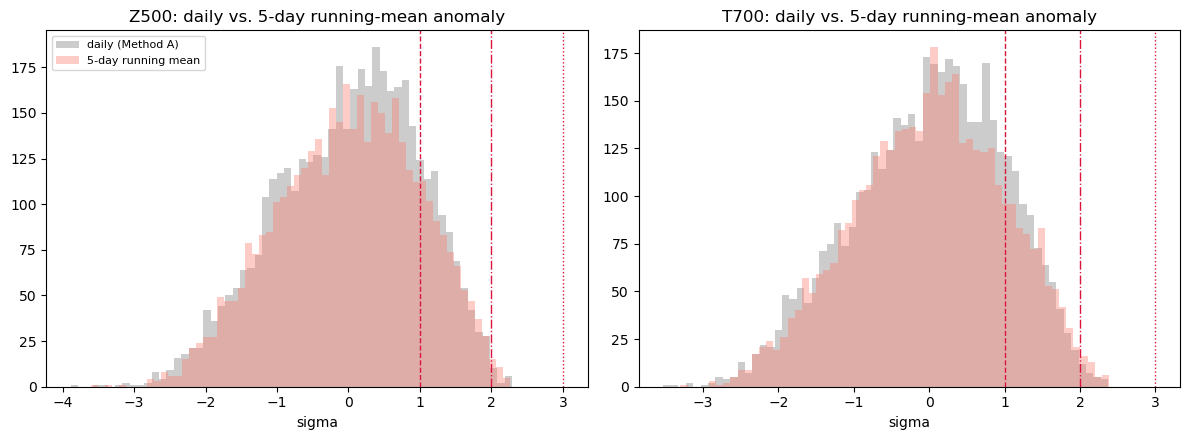


304 episodes found using 5-day running-mean anomalies (min_duration=1)


n_events  mean_duration  max_duration
variable                   threshold_sd                                       
500 hPa height (ridging)   1                  139       5.179856          18.0
                           2                   13       1.923077           3.0
700 hPa temperature (warm) 1                  136       5.272059          19.0
                           2                   16       2.625000           7.0

In [48]:
ROLL_WINDOW = MIN_DURATION  # 5-day running mean, matching the persistence window used throughout


def rolling_mean_per_year(series, window):
    """Centered rolling mean computed independently within each year's Jan-Apr
    block, so the window never bridges the real Apr->Jan gap between years."""
    return series.groupby(series.index.year).transform(
        lambda g: g.rolling(window, center=True).mean()
    )


df_roll = pd.DataFrame({
    'z500': rolling_mean_per_year(df['z500'], ROLL_WINDOW),
    't700': rolling_mean_per_year(df['t700'], ROLL_WINDOW),
}, index=df.index).dropna()  # drops the (window-1)/2 edge days of each year's record

for col in ['z500', 't700']:
    clim_mean, clim_std = climatology_dict(df_roll.index, df_roll[col].values)
    m = lookup_climatology(df_roll.index, clim_mean)
    s = lookup_climatology(df_roll.index, clim_std)
    trend = fit_year_trend(df_roll[col].values, m, df_roll.index.year.values, label=f'{col} (5-day mean)')
    df_roll[f'{col}_sanom'] = (df_roll[col] - (m + trend)) / s

print(f'\nRaw daily std:          z500={df["z500_sanom"].std():.4f}, t700={df["t700_sanom"].std():.4f}')
print(f'5-day running-mean std: z500={df_roll["z500_sanom"].std():.4f}, t700={df_roll["t700_sanom"].std():.4f}')
print('(barely smaller -- Z500/T700 are already strongly autocorrelated day-to-day, '
      'so averaging 5 correlated days does not reduce variance the way averaging 5 '
      'independent samples would.)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ['z500_sanom', 't700_sanom'], ['Z500', 'T700']):
    #ax.hist(df[col], bins=60, color='0.75', edgecolor='none', alpha=0.4, label='daily (Method A)')
    ax.hist(df[col], bins=60, color='grey', edgecolor='none', alpha=0.4, label='daily (Method A)')
    #ax.hist(df_roll[col], bins=60, color='#2a78d6', edgecolor='none', alpha=0.5, label='5-day running mean')
    ax.hist(df_roll[col], bins=60, color='salmon', edgecolor='none', alpha=0.4, label='5-day running mean')
    for sd, ls in zip(THRESHOLDS, ['--', '-.', ':']):
        ax.axvline(sd, color='crimson', linestyle=ls, linewidth=1)
    ax.set_title(f'{label}: daily vs. 5-day running-mean anomaly')
    ax.set_xlabel('sigma')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# min_duration=1: the 5-day persistence requirement is already baked into the
# running mean itself, so we only need the smoothed value to clear the
# threshold -- requiring 5 MORE consecutive days of that would double-count
# persistence and demand a stricter ~9-day real episode.
events_roll = []
for col, label in VARS:
    sanom = df_roll[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(df_roll.index, sanom, threshold=thr, min_duration=1)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_roll.append(ev)

events_methodA_roll = pd.concat(events_roll, ignore_index=True)
events_methodA_roll = events_methodA_roll.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'\n{len(events_methodA_roll)} episodes found using 5-day running-mean anomalies (min_duration=1)')
events_methodA_roll.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

**Findings:**

- **Individual days do reach 2 sigma.** 15 of 4329 days for Z500, 26 of 4329
  for T700 (0 days ever reach 3 sigma). The histogram's right tail visibly
  extends past the +2 SD line for both variables -- confirming the earlier
  "no event" result was always about *sustained 5-day persistence*, not an
  absence of single extreme days.
- **The 5-day running-mean definition does surface genuine >= 2 sigma
  episodes**, including a 7-day T700 episode (2015-02-12 to 02-18, peak
  2.39 sigma) and the March 2004 episode extending to 4 days (peak 2.36
  sigma) -- both longer than anything found under the strict daily-every-day
  persistence rule in Sections 3-4. This happens even though the smoothed
  series' own standard deviation is barely smaller than the raw daily
  series': the real effect isn't a shrinking sigma, it's that the running-mean
  definition only requires the *already-smoothed* 5-day signal to clear the
  bar, rather than requiring every individual one of 5 raw days to
  individually clear it (an AND over 5 noisy conditions that a persistent-but-
  not-perfectly-steady ridge can easily fail even while its underlying 5-day
  character stays strong).
- **Takeaway:** "no 2-sigma event" in Sections 3-4 is specific to one
  particular (reasonable, but strict) definition of persistence -- continuous
  daily exceedance for 5 straight days. Redefining persistence around a
  smoothed quantity is an equally valid choice and gives a different, less
  conservative answer. Which definition to use depends on the downstream
  application (e.g. day-to-day snowpack/drought impacts plausibly care about
  the smoothed multi-day character more than a single-day technicality).